# Inland Excess Water (IEW) Monitoring — Spectral ResUNet (rare-class focused)

Goal: raise F1 on the rare water-related classes (soil seriously / moderately / slightly affected, vegetation affected) without giving up the easy classes.

## Why the earlier backbones scored badly on rare classes

The ground truth was produced by **per-pixel thresholding of SWIR1, NDVI, NDMI and a (SWIR1−RED)/(SWIR1+RED) index** (see `docs/PAPER_WORKFLOW.md` §3.3). A plain per-pixel gradient-boosted classifier, with no spatial context at all, reaches roughly F1 ≈ 70 / 52 / 70 on the three soil classes and ≈ 79 on vegetation on the test scenes. SegFormer-B0 (notebook 09) got 25 / 28 / 40 / 56. Three things caused that gap, and this notebook fixes each one:

| Problem in 01–09 | Fix here |
|---|---|
| Labels are pixel-wise spectral thresholds, but SegFormer predicts at 1/4 resolution and upsamples | Full-resolution residual U-Net **plus a 1×1-conv spectral branch** that classifies each pixel from its own spectrum |
| The indices the labels were built from are not given to the network | **6 spectral indices** added as input channels (NDVI, NDMI, NDWI, MNDWI, SWIR1−RED, SWIR1/SWIR2) |
| Sentinel-1 was loaded but unused | **S1 (3 channels)** fused with S2 → 20 input channels |
| Uniform patch sampling: ~92 % of pixels are "not affected", soil classes are 0.3 % | **Class-aware patch sampling** — 65 % of each epoch's patches are drawn from locations containing rare classes |
| Strong inverse-frequency weights + GDL make the model over-predict rare classes (high recall, 25–45 % precision) | Mild (inverse-sqrt) weights, CE + Dice, then **post-hoc logit-bias calibration** fitted on held-out scenes to maximise macro-F1 |
| Best checkpoint chosen by val loss on the *test* scenes | Checkpoint chosen by **macro-F1 on two held-out training scenes**; test scenes are only touched in the final evaluation |

## Run order

Run all cells top to bottom. Training is **resumable**: if the kernel dies, re-run all cells and it continues from the last finished epoch. Set `QUICK_TEST = True` in the config cell for a 2-minute end-to-end dry run before committing to the full run (~4 h training + ~40 min evaluation on CPU).

## 1. Imports and configuration

In [1]:
import json
import math
import time
from pathlib import Path

import numpy as np
import yaml
import rasterio
from rasterio.windows import Window
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

QUICK_TEST = False          # True = tiny dry run of the whole notebook (does not touch real checkpoints)

SEED              = 0
PATCH             = 96      # training patch size (must be divisible by 16)
GRID_STRIDE       = 48      # candidate patch locations are indexed on this grid
BATCH_SIZE        = 16
EPOCHS            = 30
SAMPLES_PER_EPOCH = 4000
VAL_PATCHES       = 600
MAX_LR            = 1e-3
WEIGHT_DECAY      = 1e-4
RESUME            = True
TTA               = True    # horizontal-flip test-time augmentation at full-scene inference

# Two training scenes (one per site) held out for checkpoint selection and calibration.
VAL_SCENES = ["BNPI_20230208", "KNPI_20220310"]

# Share of each epoch's patches drawn from locations containing a given class
# (compact class ids). The remaining 35 % are sampled uniformly.
CLASS_SHARE = {0: 0.05, 1: 0.20, 2: 0.20, 3: 0.10, 4: 0.10}

if QUICK_TEST:
    EPOCHS, SAMPLES_PER_EPOCH, VAL_PATCHES, TTA = 1, 64, 32, False

TAG       = "spectral_resunet" + ("_quicktest" if QUICK_TEST else "")
CKPT_DIR  = Path("outputs/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = CKPT_DIR / f"{TAG}_best.pt"
LAST_PATH = CKPT_DIR / f"{TAG}_last.pt"
CAL_PATH  = CKPT_DIR / f"{TAG}_calibration.json"

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {device} | threads: {torch.get_num_threads()}")

PyTorch 2.14.1+cpu | device: cpu | threads: 8


## 2. Data pipeline

Class encoding: raw labels 2–7 → compact ids 0–5; everything else (cloud 10, shadow 11, nodata) → 255 and is ignored by the loss and by every metric.

Input tensor (20 channels): 11 standardised S2 bands · 6 spectral indices · 3 standardised S1 channels.

In [2]:
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config["dataset_root"])
LOCAL_ROOT = Path("C:/E/S5/Deep_Learning/dataset/tifs_FINAL")
if not dataset_root.exists() and LOCAL_ROOT.exists():
    dataset_root = LOCAL_ROOT
print(f"Dataset root: {dataset_root}")

IGNORE = 255
NUM_CLASSES = 6
CLASS_NAMES = [
    "Open surface water (raw 2)",
    "Soil seriously affected (raw 3)",
    "Soil moderately affected (raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected (raw 6)",
    "Not affected (raw 7)",
]
GT_LUT = np.full(256, IGNORE, dtype=np.uint8)
for raw, cls in {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}.items():
    GT_LUT[raw] = cls

# Band order: B01 B02 B03 B04 B05 B06 B07 B08 B8A B11 B12
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)
IN_CHANNELS = 11 + 6 + 3


def make_features(s2_raw: np.ndarray, s1: np.ndarray) -> np.ndarray:
    """(11,H,W) raw S2 digital numbers + (3,H,W) S1 dB -> (20,H,W) float32 model input."""
    s2 = s2_raw.astype(np.float32) / 10000.0
    eps = 1e-6
    green, red, nir, nir_n, swir1, swir2 = s2[2], s2[3], s2[7], s2[8], s2[9], s2[10]
    indices = np.stack([
        (nir - red) / (nir + red + eps),            # NDVI
        (nir_n - swir1) / (nir_n + swir1 + eps),    # NDMI
        (green - nir) / (green + nir + eps),        # NDWI
        (green - swir1) / (green + swir1 + eps),    # MNDWI
        (swir1 - red) / (swir1 + red + eps),        # SWIR1-RED soil-moisture index
        (swir1 - swir2) / (swir1 + swir2 + eps),    # SWIR ratio
    ])
    s2n = (s2 - S2_MEAN[:, None, None]) / S2_STD[:, None, None]
    s1n = (s1.astype(np.float32) - S1_MEAN[:, None, None]) / S1_STD[:, None, None]
    x = np.concatenate([s2n, indices * 2.0, s1n], axis=0)
    return np.clip(np.nan_to_num(x, nan=0.0, posinf=6.0, neginf=-6.0), -6.0, 6.0).astype(np.float32)


class Scene:
    """One aligned S2/S1/GT scene. GT is held in RAM; S2/S1 are read by window."""

    def __init__(self, split_dir: Path, filename: str):
        self.name = Path(filename).stem
        self.s2_path = split_dir / "S2" / filename
        self.s1_path = split_dir / "S1" / filename
        gt_path = split_dir / "GT" / filename
        for p in (self.s1_path, gt_path):
            if not p.exists():
                raise FileNotFoundError(f"Missing file: {p}")
        with rasterio.open(gt_path) as src:
            raw = np.nan_to_num(src.read(1), nan=0.0)
        self.gt = GT_LUT[np.clip(raw, 0, 255).astype(np.uint8)]
        self.H, self.W = self.gt.shape
        self._s2 = None
        self._s1 = None

    def read(self, r: int, c: int, h: int, w: int):
        if self._s2 is None:
            self._s2 = rasterio.open(self.s2_path)
            self._s1 = rasterio.open(self.s1_path)
        win = Window(c, r, w, h)
        return self._s2.read(window=win), self._s1.read(window=win)


def load_scenes(split: str):
    split_dir = dataset_root / "tifs" / split
    if not split_dir.exists():
        split_dir = dataset_root / split
    files = sorted(p.name for p in (split_dir / "S2").glob("*.tif"))
    if not files:
        raise FileNotFoundError(f"No .tif files under {split_dir / 'S2'}")
    return [Scene(split_dir, fn) for fn in files]


all_train = load_scenes("Train")
missing = set(VAL_SCENES) - {s.name for s in all_train}
assert not missing, f"VAL_SCENES not found in Train split: {missing}"
train_scenes = [s for s in all_train if s.name not in VAL_SCENES]
val_scenes   = [s for s in all_train if s.name in VAL_SCENES]
print(f"Train scenes: {len(train_scenes)} | held-out val scenes: {[s.name for s in val_scenes]}")

Dataset root: C:\E\S5\Deep_Learning\dataset\tifs_FINAL
Train scenes: 12 | held-out val scenes: ['BNPI_20230208', 'KNPI_20220310']


### Patch index and class-aware sampler

Every candidate patch location gets a per-class pixel count (via integral images), so each epoch can deliberately draw patches that contain the rare classes.

In [3]:
def window_counts(mask: np.ndarray, size: int, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    """Number of True pixels in every size x size window whose top-left is (rows[i], cols[j])."""
    H, W = mask.shape
    integral = np.zeros((H + 1, W + 1), dtype=np.int32)
    integral[1:, 1:] = mask.cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
    r0, c0 = rows[:, None], cols[None, :]
    return (integral[r0 + size, c0 + size] - integral[r0, c0 + size]
            - integral[r0 + size, c0] + integral[r0, c0])


class PatchIndex:
    def __init__(self, scenes, patch: int, stride: int, min_valid: float = 0.10):
        sid, rr, cc, cnt = [], [], [], []
        for i, sc in enumerate(scenes):
            rows = np.arange(0, sc.H - patch + 1, stride)
            cols = np.arange(0, sc.W - patch + 1, stride)
            counts = np.stack([window_counts(sc.gt == k, patch, rows, cols)
                               for k in range(NUM_CLASSES)], axis=-1).reshape(-1, NUM_CLASSES)
            R, C = np.meshgrid(rows, cols, indexing="ij")
            keep = counts.sum(1) >= min_valid * patch * patch
            sid.append(np.full(int(keep.sum()), i, dtype=np.int32))
            rr.append(R.ravel()[keep]); cc.append(C.ravel()[keep]); cnt.append(counts[keep])
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)
        self.counts = np.concatenate(cnt).astype(np.int64)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        """Indices for one epoch: uniform share + class-targeted shares."""
        picks = []
        for cls, share in CLASS_SHARE.items():
            w = np.sqrt(self.counts[:, cls].astype(np.float64))
            if w.sum() > 0:
                picks.append(rng.choice(len(self), size=int(round(n * share)), p=w / w.sum()))
        n_rest = n - sum(len(p) for p in picks)
        picks.append(rng.choice(len(self), size=n_rest))
        idx = np.concatenate(picks)
        rng.shuffle(idx)
        return idx


class PatchDataset(Dataset):
    def __init__(self, scenes, index: PatchIndex, picks: np.ndarray, patch: int,
                 train: bool, jitter: int = 0, seed: int = 0):
        self.scenes, self.index, self.picks = scenes, index, picks
        self.patch, self.train, self.jitter = patch, train, jitter
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.picks)

    def __getitem__(self, i):
        k = self.picks[i]
        sc = self.scenes[self.index.scene_id[k]]
        r, c = int(self.index.r[k]), int(self.index.c[k])
        if self.train and self.jitter:
            r = int(np.clip(r + self.rng.integers(-self.jitter, self.jitter + 1), 0, sc.H - self.patch))
            c = int(np.clip(c + self.rng.integers(-self.jitter, self.jitter + 1), 0, sc.W - self.patch))
        s2, s1 = sc.read(r, c, self.patch, self.patch)
        x = make_features(s2, s1)
        y = sc.gt[r:r + self.patch, c:c + self.patch]
        if self.train:
            if self.rng.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
            if self.rng.random() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
            k90 = int(self.rng.integers(0, 4))
            if k90:
                x, y = np.rot90(x, k90, axes=(1, 2)), np.rot90(y, k90, axes=(0, 1))
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y).astype(np.int64)))


t0 = time.time()
train_index = PatchIndex(train_scenes, PATCH, GRID_STRIDE)
val_index   = PatchIndex(val_scenes, PATCH, PATCH)
print(f"Patch index built in {time.time() - t0:.0f}s | train locations: {len(train_index):,} | val locations: {len(val_index):,}")

# Natural class frequency of the training scenes -> mild inverse-sqrt class weights.
train_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for sc in train_scenes:
    train_pixels += np.bincount(sc.gt.ravel(), minlength=256)[:NUM_CLASSES]
freq = train_pixels / train_pixels.sum()
class_weights = (1.0 / freq) ** 0.5
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)
print("\nClass frequency in training scenes and loss weights:")
for k in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[k]:<34s} {100 * freq[k]:6.2f} %   weight {class_weights[k]:.2f}")

# Fixed validation patches (same class-aware mix, so rare classes are well represented).
val_picks = val_index.sample(VAL_PATCHES, np.random.default_rng(SEED + 12345))
val_loader = DataLoader(PatchDataset(val_scenes, val_index, val_picks, PATCH, train=False),
                        batch_size=32, shuffle=False, num_workers=0)

# What the sampler does to the class balance the network sees:
probe = train_index.sample(2000, np.random.default_rng(SEED))
seen = train_index.counts[probe].sum(0) / train_index.counts[probe].sum()
print("\nPixel share per class in sampled training patches:", " ".join(f"{100 * v:.1f}%" for v in seen))

Patch index built in 66s | train locations: 77,180 | val locations: 3,322

Class frequency in training scenes and loss weights:
  Open surface water (raw 2)           3.66 %   weight 0.58
  Soil seriously affected (raw 3)      0.32 %   weight 1.96
  Soil moderately affected (raw 4)     0.41 %   weight 1.73
  Soil slightly affected (raw 5)       2.22 %   weight 0.75
  Vegetation affected (raw 6)          1.65 %   weight 0.87
  Not affected (raw 7)                91.73 %   weight 0.12

Pixel share per class in sampled training patches: 7.8% 1.0% 1.3% 5.5% 3.2% 81.2%


## 3. Model — Spectral ResUNet

- **Spatial branch:** 5-level residual U-Net with squeeze-and-excitation, first level at full resolution, so thin features and class boundaries are not blurred by a strided stem.
- **Spectral branch:** three 1×1 convolutions — a per-pixel MLP over the 20 input channels. It cannot see neighbours, so it learns the threshold-like spectral rules the labels were built from. It also gets its own auxiliary loss during training.
- **Fusion:** both branches are concatenated at full resolution and classified by a 3×3 + 1×1 head.

In [4]:
class SEBlock(nn.Module):
    """Squeeze-and-excitation: re-weights channels using global context."""
    def __init__(self, ch: int, r: int = 8):
        super().__init__()
        self.fc1 = nn.Conv2d(ch, max(ch // r, 8), 1)
        self.fc2 = nn.Conv2d(max(ch // r, 8), ch, 1)

    def forward(self, x):
        w = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(w))))


class ResBlock(nn.Module):
    """Conv-BN-ReLU x2 with SE and a (projected) identity shortcut."""
    def __init__(self, cin: int, cout: int):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.se = SEBlock(cout)
        self.skip = None if cin == cout else nn.Sequential(
            nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        idt = x if self.skip is None else self.skip(x)
        y = F.relu(self.b1(self.c1(x)))
        y = self.se(self.b2(self.c2(y)))
        return F.relu(y + idt)


class SpectralResUNet(nn.Module):
    """Full-resolution residual U-Net + a per-pixel spectral branch.

    Spatial branch: 5-level ResUNet (1, 1/2, 1/4, 1/8, 1/16).
    Spectral branch: 1x1 convs only, so it sees each pixel's spectrum with no
    spatial mixing. Both are fused at full resolution before the classifier.
    """
    def __init__(self, in_ch: int = 20, num_classes: int = 6,
                 widths=(32, 64, 128, 192, 256), spec_ch: int = 64):
        super().__init__()
        self.spectral = nn.Sequential(
            nn.Conv2d(in_ch, spec_ch, 1, bias=False), nn.BatchNorm2d(spec_ch), nn.ReLU(inplace=True),
            nn.Conv2d(spec_ch, spec_ch, 1, bias=False), nn.BatchNorm2d(spec_ch), nn.ReLU(inplace=True),
            nn.Conv2d(spec_ch, spec_ch, 1, bias=False), nn.BatchNorm2d(spec_ch), nn.ReLU(inplace=True),
        )
        self.enc = nn.ModuleList()
        c = in_ch
        for w in widths:
            self.enc.append(ResBlock(c, w))
            c = w
        self.bottleneck = ResBlock(widths[-1], widths[-1])
        self.dec = nn.ModuleList()
        for w_skip in reversed(widths[:-1]):
            self.dec.append(ResBlock(c + w_skip, w_skip))
            c = w_skip
        self.fuse = nn.Sequential(
            nn.Conv2d(widths[0] + spec_ch, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.Dropout2d(0.1),
        )
        self.head = nn.Conv2d(64, num_classes, 1)
        self.spec_head = nn.Conv2d(spec_ch, num_classes, 1)   # auxiliary, training only

    def forward(self, x, return_aux: bool = False):
        spec = self.spectral(x)
        skips, y = [], x
        for i, blk in enumerate(self.enc):
            if i > 0:
                y = F.max_pool2d(y, 2)
            y = blk(y)
            skips.append(y)
        y = self.bottleneck(y)
        for blk, s in zip(self.dec, reversed(skips[:-1])):
            y = F.interpolate(y, size=s.shape[2:], mode="bilinear", align_corners=False)
            y = blk(torch.cat([y, s], 1))
        logits = self.head(self.fuse(torch.cat([y, spec], 1)))
        if return_aux:
            return logits, self.spec_head(spec)
        return logits

model = SpectralResUNet(in_ch=IN_CHANNELS, num_classes=NUM_CLASSES).to(device)
n_params = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    model.eval()
    _out = model(torch.randn(2, IN_CHANNELS, PATCH, PATCH, device=device))
print(f"SpectralResUNet: {n_params / 1e6:.2f}M params | forward {(2, IN_CHANNELS, PATCH, PATCH)} -> {tuple(_out.shape)}")
del _out

SpectralResUNet: 5.23M params | forward (2, 20, 96, 96) -> (2, 6, 96, 96)


## 4. Loss and metrics

Loss = weighted cross-entropy + 0.5 · soft Dice (averaged over the classes present in the batch) + 0.3 · weighted cross-entropy on the spectral branch's auxiliary output.

Metrics are computed from a confusion matrix. **Macro-F1** (unweighted mean over classes) is the headline number, because a pixel-weighted average is dominated by the "not affected" class and hides the rare ones.

In [5]:
class CEDiceLoss(nn.Module):
    def __init__(self, weight: torch.Tensor, dice_weight: float = 0.5):
        super().__init__()
        self.register_buffer("weight", weight)
        self.dice_weight = dice_weight

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        valid = target != IGNORE
        if not valid.any():
            return logits.sum() * 0.0
        ce = F.cross_entropy(logits, target, weight=self.weight, ignore_index=IGNORE)
        t = torch.where(valid, target, torch.zeros_like(target))
        onehot = F.one_hot(t, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid[:, None]
        probs = F.softmax(logits, dim=1) * valid[:, None]
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        dice = (1.0 - (2.0 * inter + 1.0) / (denom + 1.0))[present].mean()
        return ce + self.dice_weight * dice


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    """6x6 confusion matrix (rows = truth, cols = prediction) over non-ignored pixels."""
    keep = (y_true != IGNORE) & (y_pred != IGNORE)
    return np.bincount(NUM_CLASSES * y_true[keep].astype(np.int64) + y_pred[keep].astype(np.int64),
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def prf(cm: np.ndarray):
    tp = np.diag(cm).astype(np.float64)
    pr = tp / np.maximum(cm.sum(0), 1)
    rc = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return pr, rc, f1


def macro_f1(cm: np.ndarray, classes=range(NUM_CLASSES)) -> float:
    f1 = prf(cm)[2]
    present = [k for k in classes if cm[k].sum() > 0]
    return float(np.mean([f1[k] for k in present])) if present else 0.0


def report(cm: np.ndarray, title: str) -> dict:
    pr, rc, f1 = prf(cm)
    support = cm.sum(1)
    line = "=" * 86
    print(f"\n{line}\n{title}\n{line}")
    print(f"{'Cls':<4}{'Name':<36}{'Pr (%)':>9}{'Rc (%)':>9}{'F1 (%)':>9}{'Pixels':>16}")
    print("-" * 86)
    for k in range(NUM_CLASSES):
        print(f"{k:<4}{CLASS_NAMES[k]:<36}{100 * pr[k]:>9.2f}{100 * rc[k]:>9.2f}{100 * f1[k]:>9.2f}{support[k]:>16,}")
    print("-" * 86)
    w5 = support[:5] / max(support[:5].sum(), 1)
    out = {
        "f1": f1, "macro_f1_all": macro_f1(cm), "macro_f1_water": macro_f1(cm, range(5)),
        "weighted_water": (float((pr[:5] * w5).sum()), float((rc[:5] * w5).sum()), float((f1[:5] * w5).sum())),
    }
    wp, wr, wf = out["weighted_water"]
    print(f"{'':4}{'MACRO-F1, all 6 classes':<36}{'':>18}{100 * out['macro_f1_all']:>9.2f}")
    print(f"{'':4}{'MACRO-F1, water-related (raw 2-6)':<36}{'':>18}{100 * out['macro_f1_water']:>9.2f}")
    print(f"{'':4}{'Pixel-weighted, raw 2-6 (Table 1)':<36}{100 * wp:>9.2f}{100 * wr:>9.2f}{100 * wf:>9.2f}")
    print(line)
    return out


criterion = CEDiceLoss(class_weights).to(device)
aux_criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), ignore_index=IGNORE)


@torch.no_grad()
def validate(model):
    model.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    total, batches = 0.0, 0
    for x, y in val_loader:
        logits = model(x.to(device))
        total += criterion(logits, y.to(device)).item()
        batches += 1
        cm += confusion(y.numpy(), logits.argmax(1).cpu().numpy())
    return total / max(batches, 1), cm

## 5. Training

AdamW with a one-cycle learning-rate schedule (10 % warm-up, cosine decay), gradient clipping at 1.0. Each epoch draws a fresh class-aware set of patches with random jitter, flips and 90° rotations.

After every epoch the full training state is written to `*_last.pt`; the best model by validation macro-F1 goes to `*_best.pt`.

In [6]:
steps_per_epoch = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, total_steps=EPOCHS * steps_per_epoch, pct_start=0.1)

run_cfg = {"epochs": EPOCHS, "samples": SAMPLES_PER_EPOCH, "batch": BATCH_SIZE, "patch": PATCH,
           "max_lr": MAX_LR, "val_scenes": VAL_SCENES}
history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_f1": []}
start_epoch, best_score = 1, -1.0

if RESUME and LAST_PATH.exists():
    state = torch.load(LAST_PATH, map_location=device, weights_only=False)
    if state.get("run_cfg") == run_cfg:
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        history, best_score = state["history"], state["best_score"]
        start_epoch = state["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val macro-F1 so far: {100 * best_score:.2f})")
    else:
        print("Found a checkpoint from a different configuration - starting from scratch.")

print(f"Training {TAG}: epochs {start_epoch}..{EPOCHS} | {steps_per_epoch} steps/epoch | batch {BATCH_SIZE} | patch {PATCH}")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    picks = train_index.sample(SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 1000 * epoch))
    loader = DataLoader(
        PatchDataset(train_scenes, train_index, picks, PATCH, train=True,
                     jitter=GRID_STRIDE // 2, seed=SEED + epoch),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0, drop_last=False)

    model.train()
    running = 0.0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits, aux = model(x, return_aux=True)
        loss = criterion(logits, y) + 0.3 * aux_criterion(aux, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        running += loss.item()
        if step % 50 == 0:
            print(f"  epoch {epoch} step {step}/{len(loader)} loss {running / step:.4f} "
                  f"({(time.time() - t0) / step:.1f}s/step)", end="\r")

    train_loss = running / len(loader)
    val_loss, cm = validate(model)
    f1 = prf(cm)[2]
    score = macro_f1(cm)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(score)
    history["val_f1"].append([float(v) for v in f1])

    improved = score > best_score
    if improved:
        best_score = score
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_macro_f1": score}, BEST_PATH)
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "epoch": epoch, "history": history,
                "best_score": best_score, "run_cfg": run_cfg}, LAST_PATH)

    print(f"Epoch {epoch:2d}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | "
          f"val macro-F1 {100 * score:5.2f} | per-class F1 "
          + " ".join(f"{100 * v:4.1f}" for v in f1)
          + f" | {(time.time() - t0) / 60:.1f} min{' *' if improved else ''}")

print(f"\nTraining complete. Best val macro-F1: {100 * best_score:.2f} -> {BEST_PATH}")

Training spectral_resunet: epochs 1..30 | 250 steps/epoch | batch 16 | patch 96
Epoch  1/30 | train 1.9733 | val 1.2053 | val macro-F1 52.05 | per-class F1 95.8 26.0  8.6 47.6 40.4 93.8 | 12.5 min *
Epoch  2/30 | train 1.1308 | val 0.6620 | val macro-F1 64.57 | per-class F1 96.9 47.2 14.4 63.2 68.1 97.5 | 9.9 min *
Epoch  3/30 | train 0.8254 | val 0.6530 | val macro-F1 69.13 | per-class F1 97.7 59.1 44.1 57.3 58.4 98.0 | 9.9 min *
Epoch  4/30 | train 0.7128 | val 0.5935 | val macro-F1 71.81 | per-class F1 98.2 56.4 34.6 71.7 71.5 98.4 | 11.5 min *
Epoch  5/30 | train 0.6465 | val 0.4686 | val macro-F1 77.25 | per-class F1 98.6 64.7 55.7 68.0 78.5 98.0 | 13.8 min *
Epoch  6/30 | train 0.6173 | val 0.4016 | val macro-F1 78.29 | per-class F1 98.4 67.5 64.0 64.6 77.3 98.0 | 16.2 min *
Epoch  7/30 | train 0.6052 | val 0.4807 | val macro-F1 75.23 | per-class F1 98.3 63.6 52.7 60.9 77.7 98.2 | 9.8 min
Epoch  8/30 | train 0.5777 | val 0.5896 | val macro-F1 72.23 | per-class F1 97.5 56.9 42.9 6

## 6. Training curves

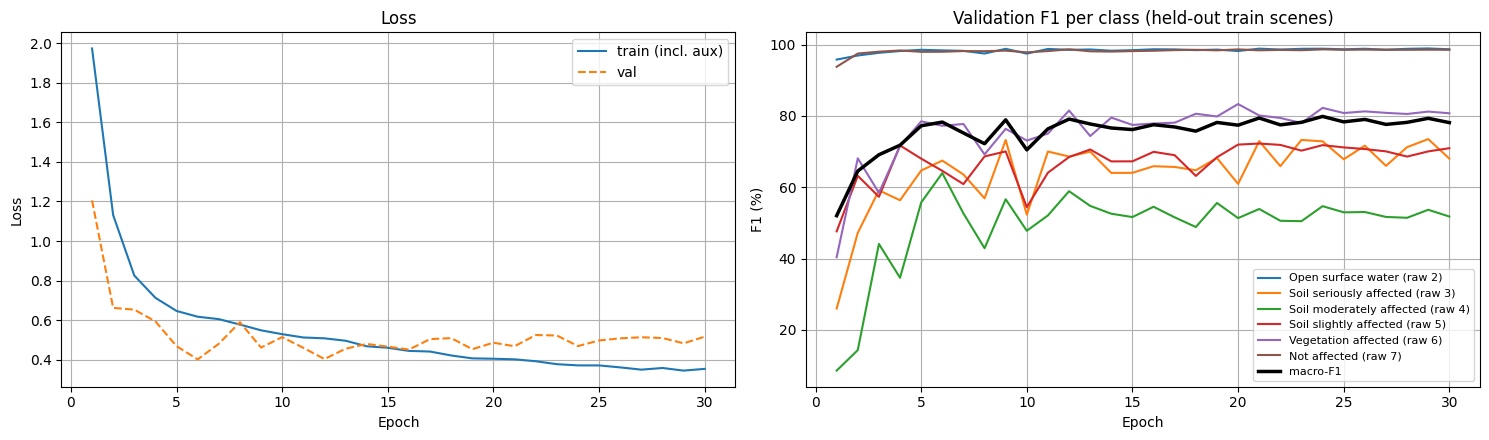

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train (incl. aux)")
axes[0].plot(ep, history["val_loss"], label="val", linestyle="--")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)

val_f1 = np.array(history["val_f1"])
for k in range(NUM_CLASSES):
    axes[1].plot(ep, 100 * val_f1[:, k], label=CLASS_NAMES[k])
axes[1].plot(ep, 100 * np.array(history["val_macro_f1"]), color="black", linewidth=2.5, label="macro-F1")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (%)"); axes[1].set_title("Validation F1 per class (held-out train scenes)")
axes[1].legend(fontsize=8); axes[1].grid(True)
plt.tight_layout()
plt.show()

## 7. Full-scene inference and logit calibration

Inference runs on 512×512 tiles with a 64-pixel context margin on every side, so there are no patch-border artefacts, and it covers every pixel of every scene.

**Calibration.** Class-aware sampling and class weights shift the network's idea of how common each class is. A per-class additive bias on the log-probabilities is fitted on the two held-out scenes (coordinate ascent, maximising macro-F1) and then applied unchanged to the test scenes. Test labels are never used for fitting.

In [8]:
ckpt = torch.load(BEST_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"Loaded best checkpoint: epoch {ckpt['epoch']} (val macro-F1 {100 * ckpt['val_macro_f1']:.2f})")

TILE, MARGIN = 512, 64


def tile_starts(length: int, tile: int):
    starts = list(range(0, max(length - tile, 0) + 1, tile))
    if starts[-1] + tile < length:
        starts.append(length - tile)
    return starts


@torch.no_grad()
def scene_logprobs(scene: Scene, max_tiles=None):
    """Yield (r0, c0, log-probabilities (6, TILE, TILE)) covering the whole scene."""
    done = 0
    for r0 in tile_starts(scene.H, TILE):
        for c0 in tile_starts(scene.W, TILE):
            ra, rb = max(r0 - MARGIN, 0), min(r0 + TILE + MARGIN, scene.H)
            ca, cb = max(c0 - MARGIN, 0), min(c0 + TILE + MARGIN, scene.W)
            s2, s1 = scene.read(ra, ca, rb - ra, cb - ca)
            x = make_features(s2, s1)
            pad = ((0, 0), (MARGIN - (r0 - ra), MARGIN - (rb - r0 - TILE)),
                   (MARGIN - (c0 - ca), MARGIN - (cb - c0 - TILE)))
            x = torch.from_numpy(np.pad(x, pad, mode="reflect"))[None].to(device)
            p = F.softmax(model(x), dim=1)
            if TTA:
                p = 0.5 * (p + F.softmax(model(x.flip(3)), dim=1).flip(3))
            logp = torch.log(p[0, :, MARGIN:MARGIN + TILE, MARGIN:MARGIN + TILE] + 1e-8)
            yield r0, c0, logp.cpu().numpy()
            done += 1
            if max_tiles and done >= max_tiles:
                return


MAX_TILES = 2 if QUICK_TEST else None

# --- collect a natural-distribution pixel sample from the held-out scenes ------------
rng = np.random.default_rng(SEED)
cal_logp, cal_y = [], []
for sc in val_scenes:
    t0 = time.time()
    for r0, c0, logp in scene_logprobs(sc, MAX_TILES):
        y = sc.gt[r0:r0 + TILE, c0:c0 + TILE]
        take = (y != IGNORE) & (rng.random(y.shape) < 0.05)
        cal_logp.append(logp[:, take].T)
        cal_y.append(y[take])
    print(f"  {sc.name}: inference {(time.time() - t0) / 60:.1f} min")
cal_logp = np.concatenate(cal_logp).astype(np.float32)
cal_y = np.concatenate(cal_y)
print(f"Calibration sample: {len(cal_y):,} pixels")


def fit_logit_bias(logp: np.ndarray, y: np.ndarray, rounds: int = 3):
    grid = np.arange(-3.0, 3.01, 0.25, dtype=np.float32)
    bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    best = macro_f1(confusion(y, logp.argmax(1)))
    for _ in range(rounds):
        for k in range(NUM_CLASSES):
            for v in grid:
                trial = bias.copy()
                trial[k] = v
                score = macro_f1(confusion(y, (logp + trial).argmax(1)))
                if score > best + 1e-6:
                    best, bias = score, trial
    return bias, best


raw_val_score = macro_f1(confusion(cal_y, cal_logp.argmax(1)))
logit_bias, cal_val_score = fit_logit_bias(cal_logp, cal_y)
print(f"Held-out scenes macro-F1: raw {100 * raw_val_score:.2f} -> calibrated {100 * cal_val_score:.2f}")
print("Logit bias per class:", np.round(logit_bias, 2).tolist())
CAL_PATH.write_text(json.dumps({"logit_bias": logit_bias.tolist(), "class_names": CLASS_NAMES}, indent=2))
del cal_logp, cal_y

Loaded best checkpoint: epoch 24 (val macro-F1 79.87)
  BNPI_20230208: inference 4.8 min
  KNPI_20220310: inference 2.8 min
Calibration sample: 1,808,391 pixels
Held-out scenes macro-F1: raw 78.40 -> calibrated 79.00
Logit bias per class: [1.75, 0.0, -0.5, 0.0, -0.25, 0.25]


## 8. Evaluation on the test scenes

Every non-cloud pixel of all 9 test scenes. Two tables: raw argmax, and with the logit bias from §7 applied. For reference, SegFormer-B0 (notebook 09) scored per-class F1 of 92.75 / 24.52 / 27.65 / 40.42 / 55.52 / 97.81 and 68.47 pixel-weighted F1 on raw 2–6; the paper's best backbone (RUPNet, Table 1) reports 81.19.

In [9]:
test_scenes = load_scenes("Test")
if QUICK_TEST:
    test_scenes = test_scenes[:2]

cm_raw = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
cm_cal = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
pred_maps = {}
for sc in test_scenes:
    t0 = time.time()
    pred_raw = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    pred_cal = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    for r0, c0, logp in scene_logprobs(sc, MAX_TILES):
        pred_raw[r0:r0 + TILE, c0:c0 + TILE] = logp.argmax(0)
        pred_cal[r0:r0 + TILE, c0:c0 + TILE] = (logp + logit_bias[:, None, None]).argmax(0)
    cm_raw += confusion(sc.gt, pred_raw)
    cm_scene = confusion(sc.gt, pred_cal)
    cm_cal += cm_scene
    pred_maps[sc.name] = pred_cal
    print(f"  {sc.name}: {(time.time() - t0) / 60:.1f} min | scene macro-F1 (calibrated) {100 * macro_f1(cm_scene):.2f}")

res_raw = report(cm_raw, "TEST SET - Spectral ResUNet, raw argmax")
res_cal = report(cm_cal, "TEST SET - Spectral ResUNet, calibrated (logit bias fitted on held-out train scenes)")

SEGFORMER_F1 = [92.75, 24.52, 27.65, 40.42, 55.52, 97.81]
print("\nPer-class F1 (%) vs SegFormer-B0 (notebook 09):")
print(f"{'Class':<36}{'SegFormer':>11}{'raw':>9}{'calibrated':>12}{'gain':>9}")
for k in range(NUM_CLASSES):
    c = 100 * res_cal["f1"][k]
    print(f"{CLASS_NAMES[k]:<36}{SEGFORMER_F1[k]:>11.2f}{100 * res_raw['f1'][k]:>9.2f}{c:>12.2f}{c - SEGFORMER_F1[k]:>+9.2f}")
print(f"{'MACRO-F1 (6 classes)':<36}{np.mean(SEGFORMER_F1):>11.2f}{100 * res_raw['macro_f1_all']:>9.2f}{100 * res_cal['macro_f1_all']:>12.2f}")
print(f"{'Pixel-weighted F1, raw 2-6':<36}{68.47:>11.2f}{100 * res_raw['weighted_water'][2]:>9.2f}{100 * res_cal['weighted_water'][2]:>12.2f}")

  BNPI_20220208: 5.1 min | scene macro-F1 (calibrated) 80.12
  BNPI_20220325: 5.0 min | scene macro-F1 (calibrated) 82.93
  BNPI_20231125: 5.0 min | scene macro-F1 (calibrated) 70.41
  BNPI_20240129: 4.9 min | scene macro-F1 (calibrated) 79.63
  KNPI_20230213: 2.8 min | scene macro-F1 (calibrated) 81.94
  KNPI_20230603: 2.8 min | scene macro-F1 (calibrated) 70.03
  KNPI_20240104: 2.9 min | scene macro-F1 (calibrated) 66.04
  KNPI_20240129: 3.6 min | scene macro-F1 (calibrated) 68.38
  KNPI_20240203: 3.1 min | scene macro-F1 (calibrated) 80.76

TEST SET - Spectral ResUNet, raw argmax
Cls Name                                   Pr (%)   Rc (%)   F1 (%)          Pixels
--------------------------------------------------------------------------------------
0   Open surface water (raw 2)              99.04    97.67    98.35       4,774,539
1   Soil seriously affected (raw 3)         64.39    72.37    68.14         313,249
2   Soil moderately affected (raw 4)        58.83    64.55    61.56    

## 9. Confusion matrix

Row-normalised (each row sums to 100 %), so it shows where the pixels of each true class end up.

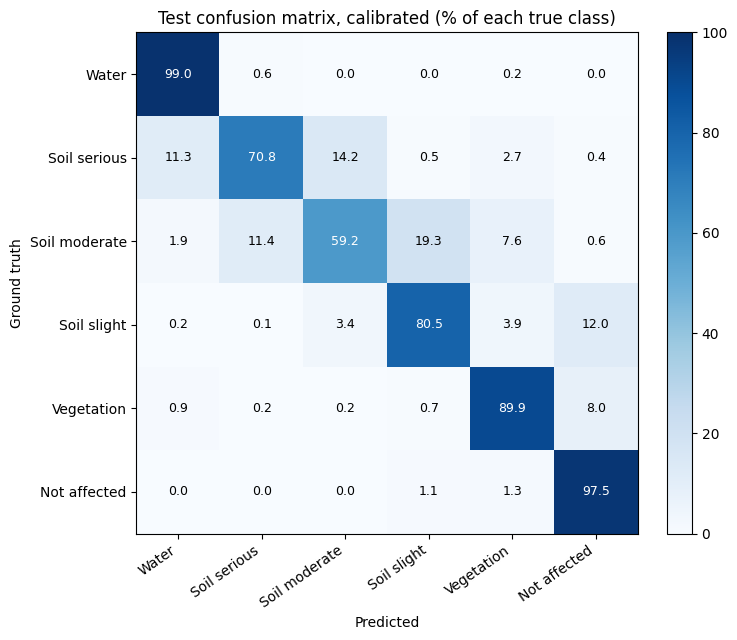

In [10]:
short = ["Water", "Soil serious", "Soil moderate", "Soil slight", "Vegetation", "Not affected"]
cm_pct = 100 * cm_cal / np.maximum(cm_cal.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title("Test confusion matrix, calibrated (% of each true class)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 10. Prediction maps

For three test scenes, the 512×512 crop richest in soil-affected pixels: true-colour S2, ground truth, prediction.

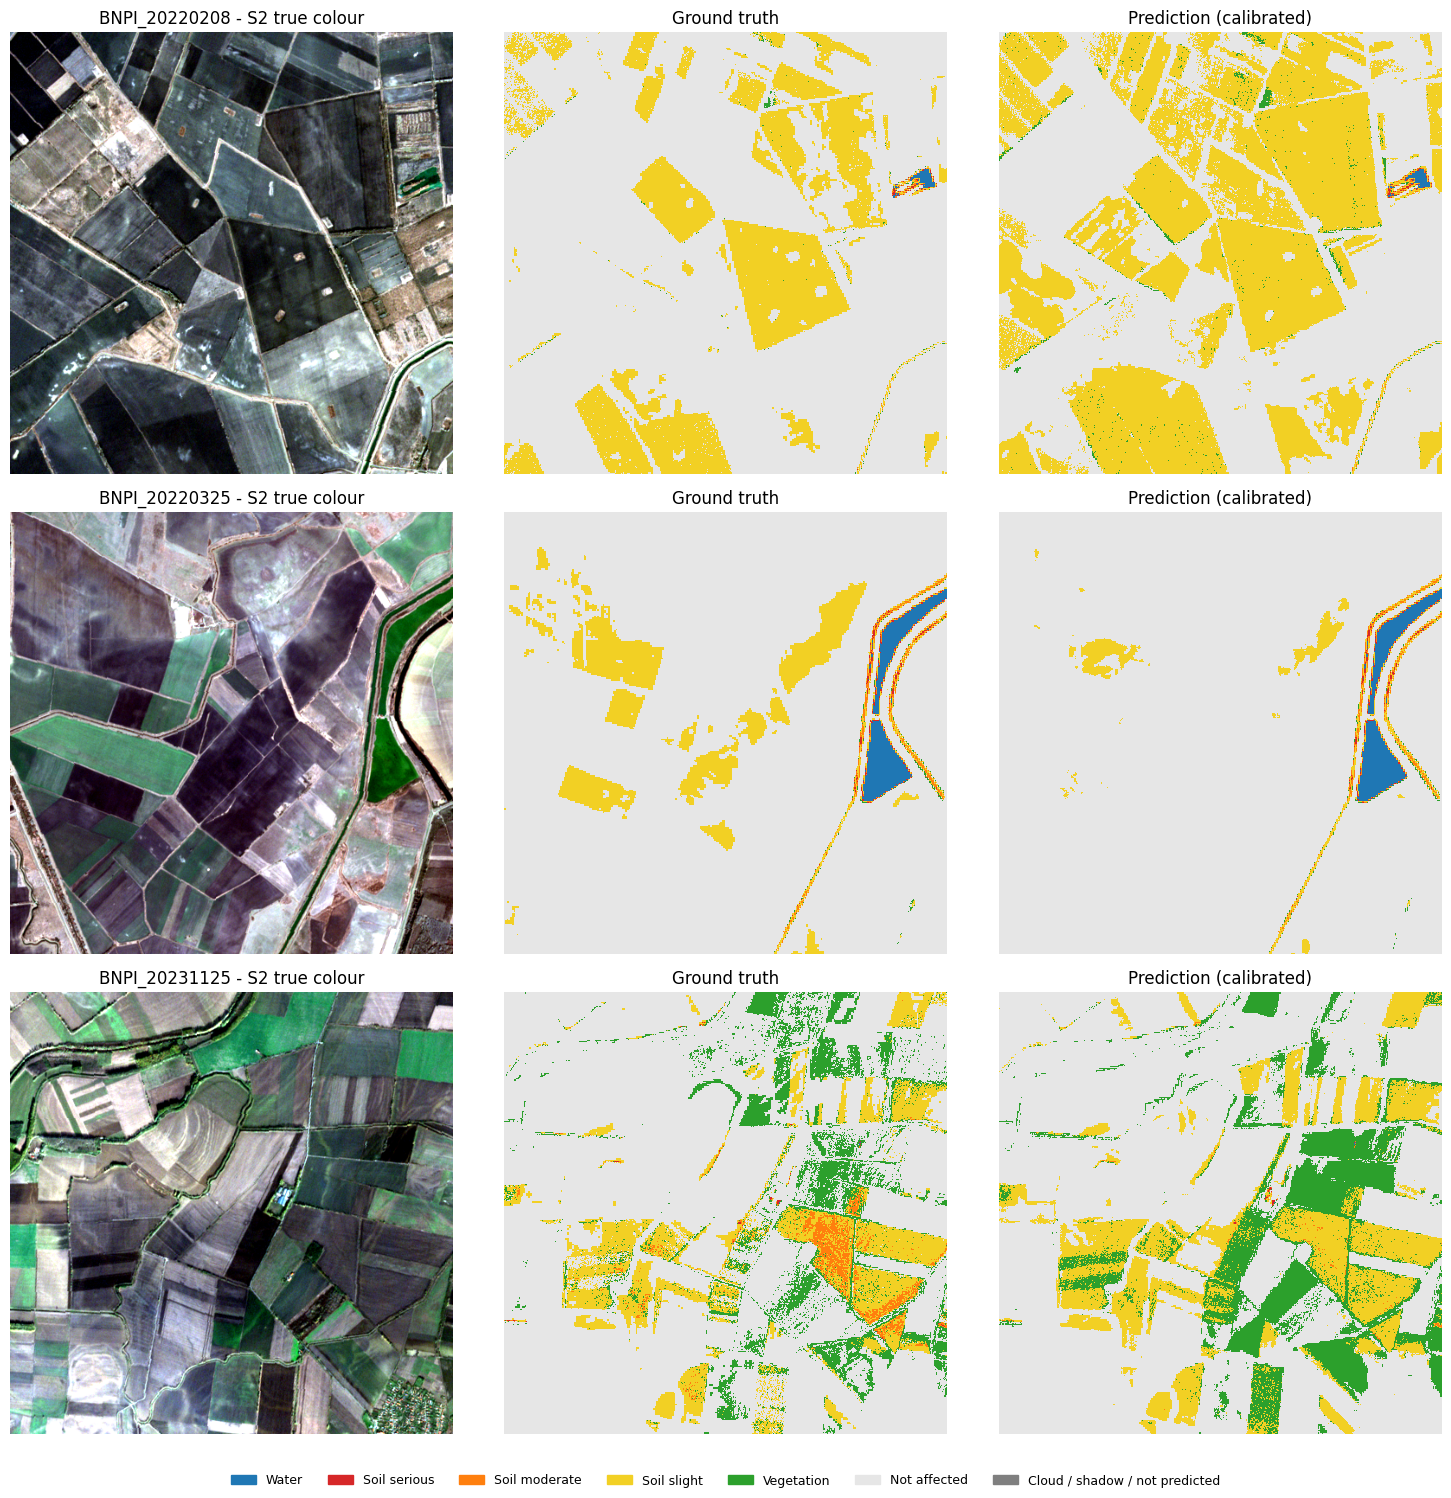

In [11]:
PALETTE = ["#1f77b4", "#d62728", "#ff7f0e", "#f2d024", "#2ca02c", "#e6e6e6", "#7f7f7f"]
cmap = ListedColormap(PALETTE)


def to_display(label_map: np.ndarray) -> np.ndarray:
    return np.where(label_map == IGNORE, NUM_CLASSES, label_map)


def stretch_rgb(rgb: np.ndarray) -> np.ndarray:
    out = np.empty_like(rgb, dtype=np.float32)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        out[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


shown = [sc for sc in test_scenes if sc.name in pred_maps][:3]
fig, axes = plt.subplots(len(shown), 3, figsize=(15, 5 * len(shown)), squeeze=False)
for row, sc in enumerate(shown):
    pred = pred_maps[sc.name]
    block = 256
    soil = (((sc.gt >= 1) & (sc.gt <= 3)) & (pred != IGNORE))
    hb, wb = sc.H // block, sc.W // block
    counts = soil[:hb * block, :wb * block].reshape(hb, block, wb, block).sum((1, 3))
    bi, bj = np.unravel_index(counts.argmax(), counts.shape)
    r0 = int(np.clip(bi * block - 128, 0, sc.H - 512))
    c0 = int(np.clip(bj * block - 128, 0, sc.W - 512))
    s2, _ = sc.read(r0, c0, 512, 512)
    rgb = stretch_rgb(np.stack([s2[3], s2[2], s2[1]], axis=-1).astype(np.float32))
    axes[row, 0].imshow(rgb); axes[row, 0].set_title(f"{sc.name} - S2 true colour")
    axes[row, 1].imshow(to_display(sc.gt[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES, interpolation="nearest")
    axes[row, 1].set_title("Ground truth")
    axes[row, 2].imshow(to_display(pred[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES, interpolation="nearest")
    axes[row, 2].set_title("Prediction (calibrated)")
    for a in axes[row]:
        a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in range(NUM_CLASSES + 1)]
fig.legend(handles, short + ["Cloud / shadow / not predicted"], loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()